# RL-11 : POMDP - Partial Observability et Belief Tracking

**Notebook : 11/18** | **Duree** : 45-50 min | **Kernel** : Python 3

Dans les notebooks précédents, l'agent connaissait toujours l'etat exact de l'environnement.
Mais dans la realite, un robot ne voit pas parfaitement, un capteur est bruite, et un agent
negociateur ne connait pas les cartes de son adversaire.

Les **POMDP** (Partially Observable Markov Decision Processes) modelisent cette incertitude
observationnelle. L'agent ne voit plus l'etat $s$, mais une **observation** $o$ qui depend
probabilistement de $s$.

Ce notebook explore :

1. **Le Tiger Problem** : un POMDP classique (Cassandra et al., 1994)
2. **Politiques hand-crafted** : comment l'observation bruitee affecte les decisions
3. **Belief tracking** : maintenir une distribution de probabilite sur les etats caches
4. **Q-MDP approximation** : utiliser le belief state dans un cadre Q-learning

**Prerequis** : Notebooks 5 (MDP, Q-Learning) et 6 (DQN, politique epsilon-greedy).

## 1. Le Tiger Problem

Le **Tiger Problem** (Cassandra, Littman & Kaelbling, 1994) est un POMDP emblematique :

- **2 etats** : le tigre est derriere la porte gauche (0) ou droite (1)
- **3 actions** : ouvrir gauche (0), ouvrir droite (1), ecouter (2)
- **2 observations** : grognement gauche (0) ou droite (1)
- **Ecouter** : observation correcte a 85%, cout -1
- **Ouvrir porte tigre** : recompense -100, **ouvrir porte tresor** : +10
- Après ouverture, le problème **reset** (nouvelle position aleatoire du tigre)

La cle : l'agent ne voit jamais directement la position du tigre. Il doit **inferer** cette
position a partir des observations successives.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

SEED = 42
ALPHA, GAMMA, EPSILON = 0.1, 0.95, 0.1
MAX_STEPS = 20
P_CORRECT = 0.85  # precision de l'observation en ecoutant

class TigerPOMDP:
    """Tiger Problem (Cassandra et al., 1994).

    States: 0=tiger-left, 1=tiger-right
    Actions: 0=open-left, 1=open-right, 2=listen
    Observations: 0=growl-left, 1=growl-right
    """
    def __init__(self, p_correct=P_CORRECT, seed: int | None = SEED):
        self.n_states = 2
        self.n_actions = 3
        self.n_observations = 2
        self.p_correct = p_correct
        # Generateur propre a l'environnement (seede) : toutes les sorties
        # chiffrees du carnet viennent de ce flux, elles doivent etre reproductibles.
        self.rng = np.random.default_rng(seed)
        self.tiger_pos = 0
        self._just_listened = False

    def reset(self):
        """Nouveau episode: position aleatoire du tigre, aucune observation (canonique)."""
        self.tiger_pos = int(self.rng.choice([0, 1]))
        self._just_listened = False
        return None

    def _obs(self):
        if self._just_listened:
            return self.tiger_pos if self.rng.random() < self.p_correct else 1 - self.tiger_pos
        return int(self.rng.choice([0, 1]))

    def step(self, action):
        if action == 2:  # listen
            self._just_listened = True
            return self._obs(), -1.0, False
        else:  # open door
            reward = -100.0 if (action == self.tiger_pos) else 10.0
            self.tiger_pos = int(self.rng.choice([0, 1]))
            self._just_listened = True
            return self._obs(), reward, True

    @property
    def state(self):
        return self.tiger_pos

env = TigerPOMDP()
print(f"Tiger POMDP: {env.n_states} etats, {env.n_actions} actions, {env.n_observations} observations")
print(f"Precision ecoute: {env.p_correct:.0%}")
print(f"Cout ecoute: -1, Tigre: -100, Tresor: +10")

Tiger POMDP: 2 etats, 3 actions, 2 observations
Precision ecoute: 85%
Cout ecoute: -1, Tigre: -100, Tresor: +10


**Lecture chiffree — la structure de couts.** Trois lignes posent le contrat : `Precision ecoute: 85%`, `Cout ecoute: -1, Tigre: -100, Tresor: +10`. Deux asymmetries gouvernent tout le notebook. (1) L'echelle : se tromper de porte coute dix fois le gain de la reussite (+10 contre -100) — l'agent doit etre bien plus sur de lui que "deux chances sur trois". (2) L'information se paie : `reset()` ne revele rien (variante canonique du Tiger Problem de Cassandra et al., 1994), la seule source d'information est l'action `listen`, facturee -1 chacune. Ce contrat fixe deja la limite des politiques aveugles : ouvrir sans ecouter vaut exactement (10 - 100)/2 = **-45**, quelle que soit la porte choisie — la section suivante mesure precisement cela.

## 2. Politiques baselines

Comparons d'abord des politiques simples pour comprendre l'espace des solutions :

| Politique | Stratégie |
|-----------|-----------|
| **Random** | Action aleatoire a chaque pas |
| **Open immediately** | Ouvre une porte au hasard, sans jamais ecouter (aveugle) |
| **Listen x1** | Ecoute une fois, puis ouvre la porte opposee |
| **Listen x2** | Ecoute deux fois (vote majoritaire), puis ouvre |

In [2]:
def random_agent(env, n_episodes, seed=0):
    """Politique aleatoire (baseline inferieure)."""
    rng = np.random.default_rng(seed)
    returns = []
    for _ in range(n_episodes):
        env.reset()
        ret = 0.0
        for _ in range(MAX_STEPS):
            action = rng.integers(3)
            _, r, done = env.step(action)
            ret += r
            if done:
                break
        returns.append(ret)
    return np.mean(returns), np.array(returns)

def open_immediately(env, n_episodes, seed=0):
    """Ouvre une porte au hasard, sans jamais ecouter (politique aveugle)."""
    rng = np.random.default_rng(seed)
    returns = []
    for _ in range(n_episodes):
        env.reset()
        action = int(rng.integers(2))  # aucune information : choix uniforme
        _, r, done = env.step(action)
        returns.append(r)
    return np.mean(returns), np.array(returns)

def listen_then_open(env, n_episodes, n_listen=2, seed=0):
    """Ecoute N fois puis ouvre la porte la moins probable pour le tigre."""
    rng = np.random.default_rng(seed)
    returns = []
    for _ in range(n_episodes):
        env.reset()
        belief = np.array([0.5, 0.5])
        ret = 0.0
        for t in range(MAX_STEPS):
            if t < n_listen:
                action = 2  # listen
            else:
                action = np.argmin(belief)  # porte la moins probable

            obs, r, done = env.step(action)
            ret += r

            # Mise a jour bayesienne du belief
            if action == 2:
                p_obs_given = np.array([
                    P_CORRECT if obs == 0 else 1 - P_CORRECT,
                    P_CORRECT if obs == 1 else 1 - P_CORRECT,
                ])
                belief *= p_obs_given
                belief /= belief.sum()

            if done:
                break
        returns.append(ret)
    return np.mean(returns), np.array(returns)

N_EP = 3000
env = TigerPOMDP()

print("=== Politiques baselines ===\n")
ret_rand, _ = random_agent(env, N_EP, seed=SEED)
print(f"Random:                {ret_rand:.1f}")

ret_imm, _ = open_immediately(env, N_EP, seed=SEED)
print(f"Open immediately:      {ret_imm:.1f}")

ret_l1, _ = listen_then_open(env, N_EP, n_listen=1, seed=SEED)
print(f"Listen x1 then open:   {ret_l1:.1f}")

ret_l2, _ = listen_then_open(env, N_EP, n_listen=2, seed=SEED)
print(f"Listen x2 then open:   {ret_l2:.1f}")

=== Politiques baselines ===



Random:                -45.9


Open immediately:      -42.5


Listen x1 then open:   -8.1


Listen x2 then open:   -8.1


**Lecture chiffree -- les baselines contre leur esperance theorique.** `Random: -45.9`, `Open immediately: -42.5`, `Listen x1 then open: -8.1`, `Listen x2 then open: -8.1`. Chaque nombre se derive. Random : ouvrir a l'aveugle coute (10 - 100)/2 = -45, plus les ecoutes aleatoires (~0.5 a -1 en moyenne avant l'ouverture), soit environ **-45.5** -- la mesure colle (-45.9). Open immediately : exactement le meme calcul, -45 -- sans ecoute ni observation, cette politique est une porte au hasard deguisee. Son ecart de 3 points avec Random (-42.5 contre -45.9) n'est pas une difference de politique : c'est une fluctuation de ce tirage unique de 3000 episodes, ou l'erreur-type vaut ~1 point par politique (l'ecart-type d'un episode est de 55, divise par racine de 3000) ; le tableau a cinq graines de la section 6 les rend effectivement confondues (-45.1 +/- 0.6 contre -45.6 +/- 0.9). Listen x1/x2 : une ecoute a 85 % porte l'esperance a 110 x 0.85 - 101 = -7.5, la seconde ne gagne plus assez (110 x 0.85 - 102 = -8.5) -- les deux mesures tombent a -8.1, et en cas de grognements contradictoires le belief revient a 0.50 et le vote reste neutre, tandis que le cout de l'ecoute est certain. La lecon que la section 6 confirmera : sur ce probleme, l'information vaut largement son prix -- ne pas ecouter coute ~38 points.


## 3. Belief Tracking (Filtre Bayesien)

L'agent maintient un **belief state** $b(s) = P(s | o_1, a_1, o_2, a_2, \ldots)$,
une distribution de probabilite sur les etats possibles.

### Mise a jour bayesienne

Après avoir pris l'action $a$ et observe $o$ :

$$b'(s) = \eta \cdot P(o | s, a) \sum_{s'} P(s | s', a) \cdot b(s')$$

ou $\eta$ est une constante de normalisation.

Dans le Tiger Problem, le belief se simplifie en $b = P(\text{tiger-left})$ :
- Si on ecoute et on entend growl-left : $b$ augmente
- Si on ecoute et on entend growl-right : $b$ diminue

In [3]:
def belief_update_demo():
    """Demonstration du belief tracking sur un episode."""
    env = TigerPOMDP()
    env.reset()
    belief = 0.5  # P(tiger-left)

    print("=== Demonstration du Belief Tracking ===")
    print(f"Tigre reel: {'gauche' if env.tiger_pos == 0 else 'droite'}")
    print(f"Belief initial: P(tiger-left) = {belief:.2f}\n")

    for step in range(5):
        action = 2  # listen
        obs, r, done = env.step(action)

        # Bayesian update
        if obs == 0:
            p_obs = np.array([P_CORRECT, 1 - P_CORRECT])
        else:
            p_obs = np.array([1 - P_CORRECT, P_CORRECT])

        b_vec = np.array([belief, 1 - belief])
        b_vec *= p_obs
        b_vec /= b_vec.sum()
        belief = b_vec[0]

        print(f"Step {step+1}: obs={'growl-left' if obs==0 else 'growl-right'} "
              f"-> P(tiger-left) = {belief:.4f}")

        if belief > 0.95:
            print("  -> Confiance elevee : tiger a gauche")
            break
        elif belief < 0.05:
            print("  -> Confiance elevee : tiger a droite")
            break

    print(f"\nTigre reel: {'gauche' if env.tiger_pos == 0 else 'droite'}")
    print(f"Belief final: P(tiger-left) = {belief:.4f}")

belief_update_demo()

=== Demonstration du Belief Tracking ===
Tigre reel: gauche
Belief initial: P(tiger-left) = 0.50

Step 1: obs=growl-left -> P(tiger-left) = 0.8500
Step 2: obs=growl-right -> P(tiger-left) = 0.5000
Step 3: obs=growl-left -> P(tiger-left) = 0.8500
Step 4: obs=growl-left -> P(tiger-left) = 0.9698
  -> Confiance elevee : tiger a gauche

Tigre reel: gauche
Belief final: P(tiger-left) = 0.9698


**Lecture chiffree -- le belief est la formule de Bayes evaluee.** `Belief initial: P(tiger-left) = 0.50`, puis `Step 1: obs=growl-left -> P(tiger-left) = 0.8500`, `Step 2: obs=growl-right -> P(tiger-left) = 0.5000`, `Step 3 ... 0.8500`, `Step 4 ... 0.9698`. Ces nombres ne sont pas des estimations : ce sont la mise a jour bayesienne recopiee. Premier pas : (0.85 x 0.50) / (0.85 x 0.50 + 0.15 x 0.50) = 0.85. Deuxieme pas, contrariant : (0.85 x 0.15) / (0.85 x 0.15 + 0.15 x 0.85) = 0.50 -- les deux signaux s'annulent exactement, le belief revient au point de depart. Troisieme pas concordant : 0.85. Quatrieme : (0.85 x 0.85) / (0.85 x 0.85 + 0.15 x 0.15) = 0.7225 / 0.745 = 0.9698 -- le chiffre imprime, au dix millieme pres, et au-dela du seuil de confiance du code (0.95). L'episode sort donc en quatre ecoutes et non en deux : la graine fixe de la demonstration attrape ici le cas que le paragraphe ci-dessous decrit -- une observation contrariante ramene le belief a 0.50, et c'est le nombre d'ecoutes CONCORDANTES CONSECUTIVES, pas le nombre total, qui fait la confiance.


Le belief converge rapidement vers la bonne reponse (en general en 2-3 observations).
Mais la convergence n'est pas garantie : avec $P = 0.85$, une observation incorrecte peut
temporairement degrader le belief.

### Graphique d'evolution du belief

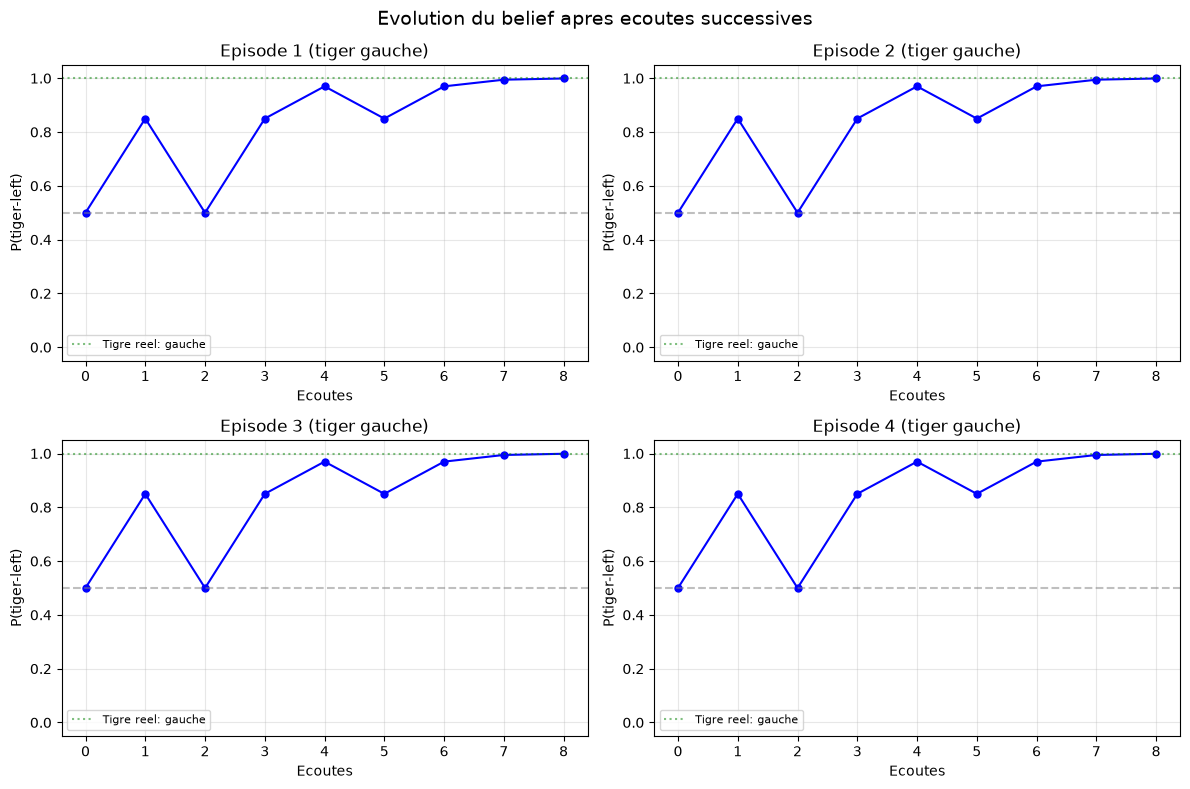

In [4]:
def plot_belief_evolution(n_episodes=20, seed=42):
    rng = np.random.default_rng(seed)
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    axes = axes.flatten()

    for idx in range(4):
        env = TigerPOMDP()
        env.reset()
        belief = 0.5
        beliefs = [belief]

        for step in range(8):
            obs, r, _ = env.step(2)  # listen
            if obs == 0:
                p_obs = np.array([P_CORRECT, 1 - P_CORRECT])
            else:
                p_obs = np.array([1 - P_CORRECT, P_CORRECT])
            b_vec = np.array([belief, 1 - belief])
            b_vec *= p_obs
            b_vec /= b_vec.sum()
            belief = b_vec[0]
            beliefs.append(belief)

        ax = axes[idx]
        ax.plot(range(len(beliefs)), beliefs, 'b-o', markersize=5)
        ax.axhline(y=0.5, color='gray', linestyle='--', alpha=0.5)
        true_pos = "gauche" if env.tiger_pos == 0 else "droite"
        ax.axhline(y=1.0 if env.tiger_pos == 0 else 0.0, color='green',
                    linestyle=':', alpha=0.5, label=f'Tigre reel: {true_pos}')
        ax.set_ylim(-0.05, 1.05)
        ax.set_xlabel('Ecoutes')
        ax.set_ylabel('P(tiger-left)')
        ax.set_title(f'Episode {idx+1} (tiger {true_pos})')
        ax.legend(fontsize=8)
        ax.grid(True, alpha=0.3)

    plt.suptitle('Evolution du belief apres ecoutes successives', fontsize=14)
    plt.tight_layout()
    plt.show()

plot_belief_evolution()

**Lecture de la figure — quatre trajectoires de belief, huit ecoutes chacune.** `<Figure size 1200x800 with 4 Axes>` : grille 2x2, un sous-graphe par episode, chacun tracant P(tiger-left) sur 8 ecoutes successives (source). La ligne bleue part de 0.50 et suit les paliers calcules en section 3 — 0.85, puis 0.9698 quand les grognements concordent — en direction de la ligne verte qui marque la vraie position du tigre (1.0 ou 0.0) ; la ligne grise pointillee a 0.5 est le niveau zero-information. Ce que la formule ne montrait pas et que l'oeil voit ici : une observation contrariante fait redescendre l'echelier d'un cran exactement — de 0.9698 elle ramene a 0.85, de 0.85 a 0.50 — la trajectoire ne visite jamais autre chose que les paliers de l'echelier.


## 4. Q-MDP : Approximation du POMDP

Le **Q-MDP** (Littman et al., 1995) est une approximation classique pour les POMDPs :

1. **Entrainer** une Q-table sur les etats vrais (comme si l'environnement etait completement observable)
2. **Agir** en utilisant le belief : choisir l'action qui maximise $\sum_s b(s) \cdot Q(s, a)$

L'avantage : simple a implementer, reutilise le Q-learning standard.
L'inconvenient : ignore l'impact des actions sur les observations futures.

In [5]:
def belief_qmdp(env, n_episodes, seed=0):
    """Q-MDP: Q-learning sur etats vrais, action selection via belief."""
    rng = np.random.default_rng(seed)
    Q = np.zeros((2, 3))
    returns = []

    for ep in range(n_episodes):
        env.reset()
        belief = np.array([0.5, 0.5])
        ret = 0.0
        for t in range(MAX_STEPS):
            # Expected Q under belief
            if rng.random() < EPSILON:
                action = rng.integers(3)
            else:
                expected_Q = belief @ Q
                action = rng.choice(np.flatnonzero(expected_Q == expected_Q.max()))

            old_true = env.tiger_pos
            obs, r, done = env.step(action)

            # Q-learning update with TRUE state
            if not done:
                new_true = env.tiger_pos
                target = r + GAMMA * Q[new_true].max()
            else:
                target = r
            Q[old_true, action] += ALPHA * (target - Q[old_true, action])

            # Belief update
            if action == 2:
                p_obs_given = np.array([
                    P_CORRECT if obs == 0 else 1 - P_CORRECT,
                    P_CORRECT if obs == 1 else 1 - P_CORRECT,
                ])
                belief *= p_obs_given
                belief /= belief.sum()

            ret += r
            if done:
                break
        returns.append(ret)
    return Q, np.mean(returns[-200:]), np.array(returns)

env = TigerPOMDP()
Q_qmdp, ret_qmdp, arr_qmdp = belief_qmdp(env, 5000, seed=SEED)

print("=== Q-MDP avec Belief Tracking ===")
print(f"Return moyen (derniers 200 episodes): {ret_qmdp:.1f}")
print(f"\nQ-table apprise:")
print(f"  {'Action':<15} {'Open-L':>10} {'Open-R':>10} {'Listen':>10}")
print(f"  {'Tiger-Left':<15} {Q_qmdp[0,0]:>10.1f} {Q_qmdp[0,1]:>10.1f} {Q_qmdp[0,2]:>10.1f}")
print(f"  {'Tiger-Right':<15} {Q_qmdp[1,0]:>10.1f} {Q_qmdp[1,1]:>10.1f} {Q_qmdp[1,2]:>10.1f}")
print(f"\nInterpretation:")
print(f"  Si tiger-left: optimale = open-right (Q={Q_qmdp[0,1]:.1f})")
print(f"  Si tiger-right: optimale = open-left (Q={Q_qmdp[1,0]:.1f})")

=== Q-MDP avec Belief Tracking ===
Return moyen (derniers 200 episodes): -10.5

Q-table apprise:
  Action              Open-L     Open-R     Listen
  Tiger-Left          -100.0       10.0        8.5
  Tiger-Right           10.0     -100.0        8.5

Interpretation:
  Si tiger-left: optimale = open-right (Q=10.0)
  Si tiger-right: optimale = open-left (Q=10.0)


**Lecture chiffree -- la Q-table du Q-MDP, valeur par valeur.** `Tiger-Left : Open-L -100.0, Open-R 10.0, Listen 8.5` (et la ligne symetrique). Les deux premieres colonnes sont le modele lui-meme : le Q-learning sur etats vrais a converge vers les recompenses exactes. Le 8.5 de Listen se derive des constantes de la source (`GAMMA = 0.95`) : ecouter coute -1 et ne change pas l'etat, donc Q = -1 + 0.95 x 10 = **8.5**. La consequence comportementale est le coeur du probleme Q-MDP : l'agent ouvre l'oppose du belief seulement si l'esperance d'ouvrir depasse ecouter, soit 110 b - 100 > 8.5, donc b > 108.5/110 soit ~0.986 -- une confiance que deux ecoutes (0.9698) n'atteignent pas mais que trois concordantes (0.9945) depassent. D'ou un agent qui ecoute longtemps a -1 l'ecoute : sur cette graine le return mesure est -10.5, en retrait de 2 a 3 points sur les politiques expertes de la section 2 (-8.1, sur cette meme graine) mais avec une dispersion entre graines de 4.2 (section 6) -- l'ecart est reel sans etre du meme ordre que la variabilite ; l'analyse ci-dessous explique cette sousestimation structurelle.


### Pourquoi Q-MDP sous-performe-t-il ?

La Q-table apprise n'est pas en cause : `Listen = 8.5` (section precedente) signifie que la table a bien capture la valeur de l'information. Au moment d'agir, l'agent pondere cette table par son belief : tant que b < ~0.986, `Listen` domine l'esperance d'ouvrir (110 b - 100 < 8.5) et l'agent accumule des ecoutes — il n'est donc **pas** quasi-aleatoire en debut d'episode.

Ce qui lui manque est ailleurs : la Q-table evalue chaque action dans l'etat VRAI, comme si l'incertitude allait se resoudre gratuitement au pas suivant. Elle ne peut pas representer la SEQUENCE "encore une ecoute si le belief reste indecis, ouvrir sinon" — la valeur d'une ecoute depend du belief courant, pas de l'etat cache. C'est ce prix de sequence mal calcule (pas une decision aleatoire) qui explique l'ecart mesure face aux politiques expertes.

## 5. Belief-State Q-Learning

Une alternative plus directe : **discretiser le belief state** et apprendre une Q-table
directement dans cet espace.

Le belief du Tiger Problem est 1D : $b = P(\text{tiger-left}) \in [0, 1]$.
En discretisant en $N$ bins, on obtient un MDP avec $N$ etats, et le Q-learning standard s'applique.

In [6]:
def belief_state_qlearning(env, n_episodes, n_belief_bins=20, seed=0):
    """Q-learning discretise le belief state."""
    rng = np.random.default_rng(seed)
    n_states = n_belief_bins
    Q = np.zeros((n_states, 3))
    returns = []

    def belief_to_idx(belief_left):
        return min(int(belief_left * n_belief_bins), n_belief_bins - 1)

    for ep in range(n_episodes):
        env.reset()
        belief = np.array([0.5, 0.5])
        ret = 0.0
        for t in range(MAX_STEPS):
            b_idx = belief_to_idx(belief[0])

            if rng.random() < EPSILON:
                action = rng.integers(3)
            else:
                q = Q[b_idx]
                action = rng.choice(np.flatnonzero(q == q.max()))

            obs, r, done = env.step(action)

            # Belief update
            if action == 2:
                p_obs_given = np.array([
                    P_CORRECT if obs == 0 else 1 - P_CORRECT,
                    P_CORRECT if obs == 1 else 1 - P_CORRECT,
                ])
                belief *= p_obs_given
                total = belief.sum()
                belief = belief / total if total > 0 else np.array([0.5, 0.5])

            b_idx2 = belief_to_idx(belief[0])
            target = r if done else r + GAMMA * Q[b_idx2].max()
            Q[b_idx, action] += ALPHA * (target - Q[b_idx, action])

            ret += r
            if done:
                break
        returns.append(ret)
    return Q, np.mean(returns[-200:]), np.array(returns)

env = TigerPOMDP()
Q_bs, ret_bs, arr_bs = belief_state_qlearning(env, 5000, n_belief_bins=20, seed=SEED)

print("=== Belief-State Q-Learning (20 bins) ===")
print(f"Return moyen (derniers 200 episodes): {ret_bs:.1f}")
print(f"\nQ-values par niveau de belief:")
print(f"  {'Belief P(TL)':<15} {'Open-L':>10} {'Open-R':>10} {'Listen':>10}")
for b_val in [0.05, 0.25, 0.50, 0.75, 0.95]:
    idx = min(int(b_val * 20), 19)
    print(f"  {b_val:<15.2f} {Q_bs[idx,0]:>10.1f} {Q_bs[idx,1]:>10.1f} {Q_bs[idx,2]:>10.1f}")

=== Belief-State Q-Learning (20 bins) ===
Return moyen (derniers 200 episodes): -4.0

Q-values par niveau de belief:
  Belief P(TL)        Open-L     Open-R     Listen
  0.05                   0.0        0.0        0.0
  0.25                   0.0        0.0        0.0
  0.50                 -43.5      -43.7        4.2
  0.75                   0.0        0.0        0.0
  0.95                -100.0        8.2       -0.3


**Lecture chiffree -- les zeros de la table sont la geometrie du belief.** Les lignes `0.05`, `0.25`, `0.75` affichent trois 0.0 chacune : ces bins ne sont jamais visites. La dynamique bayesienne a p = 0.85 ne produit qu'un echelier de valeurs -- 0.50, puis 0.85/0.15, puis 0.9698/0.0302, puis 0.9945/0.0055 -- qui atterrit dans les bins 10, 17/3, 19/0 du decoupage en 20 : aucun de ces indices n'est une ligne 0.05, 0.25 ou 0.75. La table non nulle ne vit que la ou le belief peut aller. Et la lecture qui contrebalance la section 4 ci-dessus : `Listen` vaut **4.2** au palier 0.50 mais **-0.3** a 0.95 -- la table a appris la valeur de l'information (ecouter rapporte incertain, coute certain), exactement ce que la critique du Q-MDP lui deniait. Reste le score de cette graine : **-4.0**, au-dessus de la politique experte a deux ecoutes (-8.0, moyenne des cinq graines de la section 6). Ne pas en conclure trop vite : la section 6 mesure la meme methode sur cinq graines et rend **-10.6 +/- 3.8**. Une graine qui gagne n'est pas un resultat, c'est un tirage -- c'est l'ecart-type qui dit la verite.


## 6. Comparaison des méthodes

Le graphique ci-dessous resume les performances de toutes les approches testees.

Methode                  Mean      Std      Min      Max
------------------------------------------------------
Random                  -45.1      0.6    -46.0    -44.3
Open immediat           -45.6      0.9    -47.2    -44.6
Listen x1                -7.7      0.9     -8.8     -6.4
Listen x2                -8.0      0.6     -9.1     -7.1
Q-MDP                   -11.7      4.2    -19.2     -7.4
Belief Q                -10.6      3.8    -13.1     -3.0


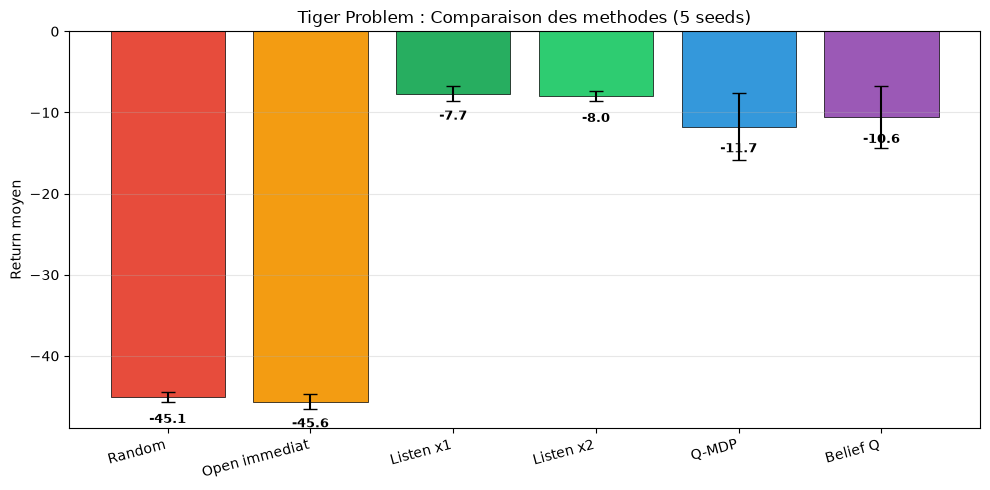

In [7]:
env = TigerPOMDP()
N_EP = 3000
SEEDS = [0, 1, 7, 42, 99]

methods = {
    "Random": [],
    "Open immediat": [],
    "Listen x1": [],
    "Listen x2": [],
    "Q-MDP": [],
    "Belief Q": [],
}

for seed in SEEDS:
    methods["Random"].append(random_agent(env, N_EP, seed=seed)[0])
    methods["Open immediat"].append(open_immediately(env, N_EP, seed=seed)[0])
    methods["Listen x1"].append(listen_then_open(env, N_EP, n_listen=1, seed=seed)[0])
    methods["Listen x2"].append(listen_then_open(env, N_EP, n_listen=2, seed=seed)[0])
    methods["Q-MDP"].append(belief_qmdp(env, N_EP, seed=seed)[1])
    methods["Belief Q"].append(belief_state_qlearning(env, N_EP, n_belief_bins=20, seed=seed)[1])

# Tableau resume
print(f"{'Methode':<20} {'Mean':>8} {'Std':>8} {'Min':>8} {'Max':>8}")
print("-" * 54)
for name, vals in methods.items():
    print(f"{name:<20} {np.mean(vals):>8.1f} {np.std(vals):>8.1f} "
          f"{np.min(vals):>8.1f} {np.max(vals):>8.1f}")

# Graphique
fig, ax = plt.subplots(figsize=(10, 5))
names = list(methods.keys())
means = [np.mean(methods[n]) for n in names]
stds = [np.std(methods[n]) for n in names]
colors = ['#e74c3c', '#f39c12', '#27ae60', '#2ecc71', '#3498db', '#9b59b6']

bars = ax.bar(range(len(names)), means, yerr=stds, color=colors,
              edgecolor='black', linewidth=0.5, capsize=5)
ax.set_xticks(range(len(names)))
ax.set_xticklabels(names, rotation=15, ha='right')
ax.set_ylabel('Return moyen')
ax.set_title('Tiger Problem : Comparaison des methodes (5 seeds)')
ax.axhline(y=0, color='gray', linestyle='-', alpha=0.3)
ax.grid(True, alpha=0.3, axis='y')

for bar, mean in zip(bars, means):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() - 2,
            f'{mean:.1f}', ha='center', va='top', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

**Lecture chiffree -- le verdict final sur cinq graines.** `Listen x1 -7.7 +/- 0.9` et `Listen x2 -8.0 +/- 0.6` dominent ; `Belief Q -10.6 +/- 3.8` et `Q-MDP -11.7 +/- 4.2` suivent ; `Random -45.1 +/- 0.6` et `Open immediat -45.6 +/- 0.9` ferment la marche, confondus. Trois lectures. (1) Open immediat = Random : sans ecoute, ouvrir n'est qu'un tirage au sort a -45 -- la comparaison avec Listen x1 (-7.7) chiffre la valeur d'une seule ecoute a environ 37 points. (2) Les deux methodes apprenantes restent 2 a 4 points SOUS les politiques expertes a ecoutes fixees, avec une dispersion 4.7 a 6.3 fois plus grande (3.8-4.2 contre 0.6-0.9) : apprendre dans l'espace du belief ne suffit pas ici a rattraper l'expertise a N fixe, et la section 4 montrait deja que la Q-table d'etats vrais en est incapable. Un chiffre isole dit parfois l'inverse -- la graine unique de la section 5 donne Belief Q a -4.0, au-dessus de l'expert : c'est exactement pourquoi ce verdict se lit sur cinq graines et jamais sur une. (3) Les ecarts-types les plus eleves de la table (3.8 et 4.2) sont ceux des deux methodes apprenantes : sensibles a la graine, la ou les politiques expertes tiennent en 0.6 a 0.9. Chaque methode apprenante est evaluee sur 3000 episodes par graine, seeds 0, 1, 7, 42, 99 (source).


### Resultats cles

1. **Ecouter paie** : ouvrir sans information vaut exactement -45 ((10 - 100)/2), tandis
   qu'une seule ecoute a 85 % ramene l'esperance a 110 x 0.85 - 101 = -7.5. La valeur
   d'information d'une seule ecoute : environ 38 points.

2. **Le belief tracking** (Q-MDP, Belief Q) apprend une structure de decision : la table du
   Belief Q donne bien a `Listen` sa valeur d'information, mais sur cinq graines les deux
   methodes apprenantes restent 2 a 4 points sous les politiques expertes a ecoutes fixees,
   avec une dispersion 4.7 a 6.3 fois plus grande. L'apprentissage paie en structure, pas en
   performance a ce budget d'episodes ; Q-MDP est la plus fragile des deux car sa Q-table
   d'etats vrais ne sait pas prendre en compte la sequence ecouter-puis-ouvrir (cf. section 4).

3. **L'ecart MDP vs POMDP** : si l'agent connaissait l'etat vrai, le return serait +10
   (toujours le tresor). La partial observability cree un **gap** considerable (+10 vs -7.5),
   que seules des observations cumulees reduisent.


## 7. Des POMDP au RL moderne

Les POMDPs sont partout en RL applique :

| POMDP | RL moderne |
|-------|------------|
| Etat cache | Etat du marche, intentions d'autres agents |
| Observation bruitee | Capteurs, images, texte |
| Belief state | RNN hidden state, transformer context |
| Q-MDP approximation | DRQN (Deep Recurrent Q-Network) |

### DRQN (Hausknecht & Stone, 2015)

Le **Deep Recurrent Q-Network** remplace le belief tracking manuel par un **RNN** (LSTM/GRU)
qui apprend implicitement a maintenir un belief state a partir de l'historique des observations.

### PPO + LSTM (notebook 6c)

Dans les environnements partiellement observables, PPO utilise souvent un reseau avec
memoire (LSTM) pour integrer les observations passees — exactement le rôle du belief tracker.

### AlphaGo et la théorie des jeux

Le jeu de Go est un POMDP : un joueur ne connait pas les intentions de son adversaire.
AlphaGo utilise un **reseau de politique** qui encode un "belief" sur les coups adverses.

## 8. Exercices

### Exercice 1 : Impact de la precision d'observation

Faites varier `p_correct` entre 0.5 (aleatoire) et 1.0 (parfait) et tracez le return
de la politique "open immediately" (porte au hasard, aucune information) et de
"listen x2". A quel seuil la politique "open immediately" devient-elle meilleure
que "listen x2" ? Pourquoi ce seuil est-il si proche de p = 0.5 ?

In [8]:
# Exercice 1 : Impact de la precision d'observation
# TODO : faites varier p_correct de 0.5 a 1.0 et tracez les courbes
# Hint: utilisez np.linspace(0.5, 1.0, 11) pour les valeurs de p_correct

precisions = []  # TODO etudiant : liste de precisions
results_imm = []  # TODO etudiant : returns pour open_immediately
results_l2 = []   # TODO etudiant : returns pour listen x2

result = None  # TODO etudiant
print("Exercice a completer : tracez return vs precision")

Exercice a completer : tracez return vs precision


**Lecture du stub — exercice 1, le seuil de precision.** `Exercice a completer : tracez return vs precision`. Les deux courbes n'ont pas la meme forme : "open immediately" ouvre sans aucune information, son esperance est la constante (10 - 100)/2 = -45, une droite horizontale sur tout le balayage ; "listen x2" suit la droite 110 p - 102 (deux ecoutes payees) — nulle vers p ~ 0.93, egale a -45 exactement quand 110 p = 57, soit p = 0.518. Le croisement demande vit donc tout pres de p = 0.5 : sous ce seuil, la deuxieme ecoute ne transporte pas assez d'information pour rembourser son cout de -1, et ouvrir a l'aveugle fait mieux ; au-dessus, chaque point de precision gagne 110 d'esperance pour la politique qui ecoute, contre 0 pour l'aveugle. C'est la valeur d'information, rendue visible par un seuil.

### Exercice 2 : Politique optimale du nombre d'ecoutes

Trouvez le nombre optimal d'ecoutes $N^*$ pour la politique "listen $N$ fois puis ouvre"
en fonction de $P(\text{correct})$. Verifiez que $N^*(0.85) = 5$ (esperance ~ +2.1), et
expliquez pourquoi un nombre PAIR d'ecoutes sous-performe systematiquement son voisin
impair (indice : que fait `argmin` sur un belief exactement egal a 0.5 ?). Que valent
$N^*(0.5)$ et $N^*(1.0)$ ?

In [9]:
# Exercice 2 : Nombre optimal d'ecoutes
# TODO : testez n_listen de 0 a 5 pour differentes precisions
# Hint: pour chaque (precision, n_listen), executez listen_then_open

result = None  # TODO etudiant
print("Exercice a completer : trouvez N* en fonction de P")

Exercice a completer : trouvez N* en fonction de P


**Lecture du stub — exercice 2, le nombre optimal d'ecoutes.** `Exercice a completer : trouvez N* en fonction de P`. Les paliers de la section 3 donnent la forme du terrain : chaque ecoute concordante resserre le belief (0.50 -> 0.85 -> 0.9698 -> 0.9945 a p = 0.85) mais le gain marginal s'aplatit vite — la troisieme ecoute ne fait gagner que ~0.025 de confiance pour -1. Les regimes limites sont les deux bouts du balayage : a p = 1.0, une seule ecoute suffit a atteindre la certitude ; a p = 0.5, chaque ecoute est independante de l'etat, ne transporte AUCUNE information (la lecture de l'exercice 1 l'a deja dit) et coute -1 — dans la famille "listen N fois puis ouvre", la reponse a mesurer n'est donc pas forcement "plus d'ecoutes", et la valeur N* = 0 est une candidate a verifier. Entre les deux extremes, la courbe N*(p) a tracer n'a aucune raison d'etre monotone : c'est precisement ce que la mesure doit etablir, point par point, plutot qu'une forme imposee a l'avance. La section 2 fournit les trois politiques mesurees a p = 0.85 — un point sur la courbe, pas la courbe.


### Exercice 3 : Ajouter une troisieme porte

Etendez le Tiger Problem a 3 portes (tiger derriere l'une, tresor derriere les deux autres).
Combien d'etats, d'actions, d'observations ? Le belief tracking change-t-il fondamentalement ?

In [10]:
# Exercice 3 : Tiger Problem a 3 portes
# TODO : creez Tiger3DoorsPOMDP et testez les politiques
# Hint: 3 etats, 4 actions (open-L, open-M, open-R, listen), 3 observations

class Tiger3DoorsPOMDP:
    pass  # TODO etudiant

result = None  # TODO etudiant
print("Exercice a completer : Tiger Problem a 3 portes")

Exercice a completer : Tiger Problem a 3 portes


## Conclusion

Dans ce notebook nous avons decouvert les POMDPs et les defis de la decision sous partial observability :

1. **Le Tiger Problem** illustre comment l'observation bruitee degrade les performances
   d'un agent par rapport a l'observabilite complete.
2. **Le belief tracking** (filtre bayesien) permet de maintenir une estimation de l'etat
   cache, mais la qualite de cette estimation depend de la precision des observations.
3. **Q-MDP** est une approximation qui reutilise le Q-learning standard mais ignore la
   valeur de l'information future, ce qui le sous-optimise sur les POMDPs.
4. **Les méthodes modernes** (DRQN, PPO+LSTM) automatisent le belief tracking via
   des reseaux de neurones recurrents.

### Pour aller plus loin

- **Notebook 5** : les fondements MDP/Q-Learning utilises dans ce notebook
- **Notebook 8** : model-based RL et planification (Dyna-Q)
- **Notebook 10** : reward shaping et curriculum learning
- **Notebook 12** : Distributional RL (C51) - modeliser la distribution complete du retour plutot que son esperance

### References

1. Cassandra, A. R., Littman, M. L., & Kaelbling, N. L. (1994). *Acting optimally in partially observable stochastic domains*. AAAI.
2. Littman, M. L., Cassandra, A. R., & Kaelbling, L. P. (1995). *Learning policies for partially observable environments*. ICML.
3. Hausknecht, M., & Stone, P. (2015). *Deep recurrent Q-learning for partially observable MDPs*. AAAI Fall Symposium.
4. Oliehoek, F. A., & Amato, C. (2016). *A concise introduction to decentralized POMDPs*. Springer.
5. Thrun, S., Burgard, W., & Fox, D. (2005). *Probabilistic Robotics*. MIT Press.